# InSAR Sea Ice Deformation - Cambridge Bay, Nunavut (Real Sentinel-1)## Replicating Chen et al. (2021) with 2023-2024 Data---**Study Area:** Cambridge Bay, Victoria Island, Nunavut, Canada (69.12N, 105.05W)  **Period:** December 2023 - May 2024 (full winter season)  **Data:** Sentinel-1 IW SLC (ascending + descending, 12-day repeat)  **Processing:** ASF HyP3 cloud (ISCE2) - FREE  ### Pipeline (following Chen et al. 2021)1. Search Sentinel-1 SLC on ASF (Section 3)2. Form consecutive 12-day InSAR pairs (Section 4)3. Submit to HyP3 cloud for ISCE2 processing (Section 5)4. Download and load processed GeoTIFFs (Sections 6-7)5. Coherence analysis (Section 8) - cf. paper Fig 4-56. Wrapped interferograms (Section 9) - cf. paper Fig 6-77. Goldstein phase filter (Section 10)8. SBAS time-series inversion (Section 11) - cf. paper Fig 8-99. 2D decomposition: horizontal + vertical (Section 12) - cf. paper Fig 10-11**Reference:** Chen et al. (2021), *Remote Sensing*, 13, 4570

## 1. Install and Import

In [1]:
!pip install -q asf_search hyp3_sdk rasterio numpy scipy matplotlib
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter
from scipy.linalg import lstsq
from scipy.ndimage import uniform_filter, zoom
from datetime import datetime, timedelta
from collections import Counter
import asf_search as asf
from rasterio.warp import transform as rio_transform
import os, glob, zipfile, rasterio, time
import warnings; warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.figsize':(14,8),'font.size':12,'figure.dpi':120})
print('All imports ready')

All imports ready


## 2. ConfigurationCambridge Bay monitoring points match paper's P1-P5 layout:5-10 km from shore, water depths 10-70 m.

In [2]:
CENTER_LAT, CENTER_LON = 69.12, -105.05
AOI = 'POLYGON((-106.0 68.8, -104.0 68.8, -104.0 69.5, -106.0 69.5, -106.0 68.8))'
START_DATE = '2018-12-01'
END_DATE   = '2019-05-31'
WAVELENGTH = 0.05546576
DESC_INC = 33.5
ASC_INC  = 39.0

# Points spread 5-10 km from shore across different water depths
# Following paper: P1=10-20m, P2=40-50m, P3=60-70m, P4=50-60m
MONITOR_POINTS = {
    'RP': (69.117, -105.052),  # Arctic Station building (land reference)
    'P1': (69.07, -105.15),    # 5 km from shore, near harbor, 10-20m depth
    'P2': (68.98, -105.40),    # 15 km SW, mid-channel, 40-50m depth
    'P3': (68.93, -105.70),    # Deep strait toward Dease Strait, 60-70m depth
    'P4': (69.00, -104.50),    # East side toward Queen Maud Gulf, 50-60m depth
    'P5': (69.14, -105.00),    # On land near coast
}
clr = {'P1':'#1f77b4','P2':'#ff7f0e','P3':'#2ca02c','P4':'#d62728','P5':'#9467bd'}
mkr = {'P1':'o','P2':'s','P3':'^','P4':'D','P5':'v'}

WORK_DIR = './insar_cambridge'
os.makedirs(f'{WORK_DIR}/desc', exist_ok=True)
os.makedirs(f'{WORK_DIR}/asc', exist_ok=True)
print(f'Study: Cambridge Bay ({CENTER_LAT}N, {CENTER_LON}W)')
print(f'Period: {START_DATE} to {END_DATE}')


Study: Cambridge Bay (69.12N, -105.05W)
Period: 2018-12-01 to 2019-05-31


## 3. Search Sentinel-1 SLC on ASF

In [3]:
print('Searching DESCENDING...')
results_desc = asf.search(
    platform=[asf.PLATFORM.SENTINEL1],
    processingLevel=asf.PRODUCT_TYPE.SLC,
    beamMode=[asf.BEAMMODE.IW],
    flightDirection=asf.FLIGHT_DIRECTION.DESCENDING,
    intersectsWith=AOI, start=START_DATE, end=END_DATE,
)
print(f'Found {len(results_desc)} descending scenes')

print('Searching ASCENDING...')
results_asc = asf.search(
    platform=[asf.PLATFORM.SENTINEL1],
    processingLevel=asf.PRODUCT_TYPE.SLC,
    beamMode=[asf.BEAMMODE.IW],
    flightDirection=asf.FLIGHT_DIRECTION.ASCENDING,
    intersectsWith=AOI, start=START_DATE, end=END_DATE,
)
print(f'Found {len(results_asc)} ascending scenes')

Searching DESCENDING...
Found 12 descending scenes
Searching ASCENDING...
Found 14 ascending scenes


In [4]:
desc_scenes = sorted(results_desc, key=lambda x: x.properties['startTime'])
asc_scenes = sorted(results_asc, key=lambda x: x.properties['startTime'])
print('=' * 90)
print('DESCENDING SCENES')
print('-' * 90)
for i, s in enumerate(desc_scenes):
    p = s.properties
    print(f'{i+1:<4} {p["startTime"][:19]:<22} {p["fileID"][:60]}')
print(f'\n{"=" * 90}')
print('ASCENDING SCENES')
print('-' * 90)
for i, s in enumerate(asc_scenes):
    p = s.properties
    print(f'{i+1:<4} {p["startTime"][:19]:<22} {p["fileID"][:60]}')

DESCENDING SCENES
------------------------------------------------------------------------------------------
1    2018-12-07T13:34:23    S1A_IW_SLC__1SDH_20181207T133423_20181207T133452_024920_02BE
2    2018-12-19T13:34:22    S1A_IW_SLC__1SDH_20181219T133422_20181219T133451_025095_02C5
3    2018-12-31T13:34:22    S1A_IW_SLC__1SDH_20181231T133422_20181231T133451_025270_02CB
4    2019-01-12T13:34:21    S1A_IW_SLC__1SDH_20190112T133421_20190112T133450_025445_02D1
5    2019-01-24T13:34:21    S1A_IW_SLC__1SDH_20190124T133421_20190124T133450_025620_02D8
6    2019-02-05T13:34:20    S1A_IW_SLC__1SDH_20190205T133420_20190205T133449_025795_02DE
7    2019-02-17T13:34:20    S1A_IW_SLC__1SDH_20190217T133420_20190217T133449_025970_02E4
8    2019-03-01T13:34:20    S1A_IW_SLC__1SDH_20190301T133420_20190301T133449_026145_02EA
9    2019-03-13T13:34:20    S1A_IW_SLC__1SDH_20190313T133420_20190313T133449_026320_02F1
10   2019-03-25T13:34:21    S1A_IW_SLC__1SDH_20190325T133421_20190325T133449_026495_02F7
1

In [5]:
# Select most common orbit track
desc_track = Counter(s.properties.get('pathNumber') for s in desc_scenes).most_common(1)[0][0]
asc_track  = Counter(s.properties.get('pathNumber') for s in asc_scenes).most_common(1)[0][0]
desc_filtered = [s for s in desc_scenes if s.properties.get('pathNumber') == desc_track]
asc_filtered  = [s for s in asc_scenes  if s.properties.get('pathNumber') == asc_track]
print(f'Descending track {desc_track}: {len(desc_filtered)} scenes')
print(f'Ascending track {asc_track}: {len(asc_filtered)} scenes')

Descending track 173: 12 scenes
Ascending track 136: 14 scenes


## 4. Form InSAR PairsDeduplicate frames, then form ALL consecutive 12-day pairs across the full season.

In [11]:
def dedup_by_date(scenes):
    seen = {}
    for s in scenes:
        date = s.properties['startTime'][:10]
        if date not in seen: seen[date] = s
    return list(seen.values())

desc_unique = sorted(dedup_by_date(desc_filtered), key=lambda s: s.properties['startTime'])
asc_unique  = sorted(dedup_by_date(asc_filtered), key=lambda s: s.properties['startTime'])
print(f'After dedup: {len(desc_unique)} desc, {len(asc_unique)} asc')

desc_stable = [s for s in desc_unique if '2018-12' <= s.properties['startTime'][:7] <= '2019-05']
asc_stable  = [s for s in asc_unique  if '2018-12' <= s.properties['startTime'][:7] <= '2019-05']

desc_pairs = [(desc_stable[i], desc_stable[i+1]) for i in range(len(desc_stable)-1)]
asc_pairs  = [(asc_stable[i], asc_stable[i+1]) for i in range(len(asc_stable)-1)]

print(f'Descending: {len(desc_stable)} scenes -> {len(desc_pairs)} pairs')
print(f'Ascending:  {len(asc_stable)} scenes -> {len(asc_pairs)} pairs')
print(f'Total HyP3 jobs: {len(desc_pairs) + len(asc_pairs)}')
print('\nDescending pairs:')
for r,s in desc_pairs:
    print(f'  {r.properties["startTime"][:10]} x {s.properties["startTime"][:10]}')
print('\nAscending pairs:')
for r,s in asc_pairs:
    print(f'  {r.properties["startTime"][:10]} x {s.properties["startTime"][:10]}')

After dedup: 12 desc, 14 asc
Descending: 12 scenes -> 11 pairs
Ascending:  14 scenes -> 13 pairs
Total HyP3 jobs: 24

Descending pairs:
  2018-12-07 x 2018-12-19
  2018-12-19 x 2018-12-31
  2018-12-31 x 2019-01-12
  2019-01-12 x 2019-01-24
  2019-01-24 x 2019-02-05
  2019-02-05 x 2019-02-17
  2019-02-17 x 2019-03-01
  2019-03-01 x 2019-03-13
  2019-03-13 x 2019-03-25
  2019-03-25 x 2019-04-06
  2019-04-06 x 2019-04-30

Ascending pairs:
  2018-12-11 x 2018-12-23
  2018-12-23 x 2019-01-04
  2019-01-04 x 2019-01-16
  2019-01-16 x 2019-01-28
  2019-01-28 x 2019-02-09
  2019-02-09 x 2019-02-21
  2019-02-21 x 2019-03-05
  2019-03-05 x 2019-03-17
  2019-03-17 x 2019-04-10
  2019-04-10 x 2019-04-22
  2019-04-22 x 2019-05-04
  2019-05-04 x 2019-05-16
  2019-05-16 x 2019-05-28


## 5. Submit InSAR Jobs to HyP3

In [7]:
from hyp3_sdk import HyP3
hyp3 = HyP3(prompt=True)
print('HyP3 authenticated')

NASA Earthdata Login username:  <redacted>
NASA Earthdata Login password:  ········


HyP3 authenticated


In [8]:
print('Submitting DESCENDING jobs...')
desc_jobs = []
for i, (ref, sec) in enumerate(desc_pairs):
    print(f'  [{i+1}/{len(desc_pairs)}] {ref.properties["startTime"][:10]} x {sec.properties["startTime"][:10]}')
    batch = hyp3.submit_insar_job(
        granule1=ref.properties['sceneName'], granule2=sec.properties['sceneName'],
        name=f'cb_desc_{i:02d}', looks='20x4',
        include_wrapped_phase=True, include_inc_map=True,
        include_displacement_maps=True, include_look_vectors=True,
        apply_water_mask=False,
    )
    desc_jobs.extend(batch.jobs)
print(f'Submitted {len(desc_jobs)} descending jobs')

Submitting DESCENDING jobs...
  [1/11] 2018-12-07 x 2018-12-19
  [2/11] 2018-12-19 x 2018-12-31
  [3/11] 2018-12-31 x 2019-01-12
  [4/11] 2019-01-12 x 2019-01-24
  [5/11] 2019-01-24 x 2019-02-05
  [6/11] 2019-02-05 x 2019-02-17
  [7/11] 2019-02-17 x 2019-03-01
  [8/11] 2019-03-01 x 2019-03-13
  [9/11] 2019-03-13 x 2019-03-25
  [10/11] 2019-03-25 x 2019-04-06
  [11/11] 2019-04-06 x 2019-04-30
Submitted 11 descending jobs


In [9]:
print('Submitting ASCENDING jobs...')
asc_jobs = []
for i, (ref, sec) in enumerate(asc_pairs):
    print(f'  [{i+1}/{len(asc_pairs)}] {ref.properties["startTime"][:10]} x {sec.properties["startTime"][:10]}')
    batch = hyp3.submit_insar_job(
        granule1=ref.properties['sceneName'], granule2=sec.properties['sceneName'],
        name=f'cb_asc_{i:02d}', looks='20x4',
        include_wrapped_phase=True, include_inc_map=True,
        include_displacement_maps=True, include_look_vectors=True,
        apply_water_mask=False,
    )
    asc_jobs.extend(batch.jobs)
print(f'Submitted {len(asc_jobs)} ascending jobs')
print(f'Total: {len(desc_jobs)+len(asc_jobs)} jobs in cloud')

Submitting ASCENDING jobs...
  [1/13] 2018-12-11 x 2018-12-23
  [2/13] 2018-12-23 x 2019-01-04
  [3/13] 2019-01-04 x 2019-01-16
  [4/13] 2019-01-16 x 2019-01-28
  [5/13] 2019-01-28 x 2019-02-09
  [6/13] 2019-02-09 x 2019-02-21
  [7/13] 2019-02-21 x 2019-03-05
  [8/13] 2019-03-05 x 2019-03-17
  [9/13] 2019-03-17 x 2019-04-10
  [10/13] 2019-04-10 x 2019-04-22
  [11/13] 2019-04-22 x 2019-05-04
  [12/13] 2019-05-04 x 2019-05-16
  [13/13] 2019-05-16 x 2019-05-28
Submitted 13 ascending jobs
Total: 24 jobs in cloud


In [10]:
all_jobs = desc_jobs + asc_jobs
print(f'Monitoring {len(all_jobs)} jobs (auto-refresh 2 min)...')
while True:
    statuses = {}
    for jb in all_jobs:
        st = hyp3.get_job_by_id(jb.job_id).status_code
        statuses[st] = statuses.get(st, 0) + 1
    print(f'[{datetime.now():%H:%M:%S}] {statuses}')
    if statuses.get('SUCCEEDED',0)+statuses.get('FAILED',0)==len(all_jobs):
        print('All done!'); break
    time.sleep(120)

Monitoring 24 jobs (auto-refresh 2 min)...
[18:02:29] {'RUNNING': 7, 'PENDING': 17}
[18:04:33] {'RUNNING': 16, 'PENDING': 8}
[18:06:36] {'RUNNING': 22, 'PENDING': 2}
[18:08:40] {'RUNNING': 24}
[18:10:43] {'RUNNING': 24}
[18:12:47] {'RUNNING': 24}
[18:14:51] {'RUNNING': 24}
[18:16:54] {'RUNNING': 24}
[18:18:58] {'RUNNING': 24}
[18:21:01] {'RUNNING': 24}
[18:23:05] {'RUNNING': 24}
[18:25:09] {'RUNNING': 24}
[18:29:16] {'SUCCEEDED': 7, 'RUNNING': 17}
[18:31:20] {'SUCCEEDED': 10, 'RUNNING': 14}
[18:33:24] {'SUCCEEDED': 16, 'RUNNING': 8}
[18:35:27] {'SUCCEEDED': 21, 'RUNNING': 3}
[18:37:31] {'SUCCEEDED': 22, 'RUNNING': 2}
[18:39:34] {'SUCCEEDED': 24}
All done!


## 6. Download and Extract Results

In [11]:
for label, jobs, sub in [('DESC',desc_jobs,'desc'),('ASC',asc_jobs,'asc')]:
    print(f'Downloading {label}...')
    for i, jb in enumerate(jobs):
        j = hyp3.get_job_by_id(jb.job_id)
        if j.status_code=='SUCCEEDED':
            j.download_files(f'{WORK_DIR}/{sub}'); print(f'  [{i+1}] {j.name}')
        else: print(f'  [{i+1}] SKIPPED ({j.status_code})')

for sub in ['desc','asc']:
    for zf in glob.glob(f'{WORK_DIR}/{sub}/*.zip'):
        with zipfile.ZipFile(zf,'r') as z: z.extractall(f'{WORK_DIR}/{sub}')
print('Download complete!')

S1AA_20181207T133423_20181219T133422_HHP012_INT80_G_ueF_D3AA.zip:   0%|          | 0/372146842 [00:00<?, ?it/s…

  [1] cb_desc_00


S1AA_20181219T133422_20181231T133422_HHP012_INT80_G_ueF_9221.zip:   0%|          | 0/364107840 [00:00<?, ?it/s…

  [2] cb_desc_01


S1AA_20181231T133422_20190112T133421_HHP012_INT80_G_ueF_CE28.zip:   0%|          | 0/370169798 [00:00<?, ?it/s…

...

  [11] cb_asc_10


S1BB_20190504T002836_20190516T002836_VVP012_INT80_G_ueF_D97C.zip:   0%|          | 0/337826828 [00:00<?, ?it/s…

  [12] cb_asc_11


S1BB_20190516T002836_20190528T002837_VVP012_INT80_G_ueF_E4C8.zip:   0%|          | 0/341165725 [00:00<?, ?it/s…

  [13] cb_asc_12
Download complete!


## 7. Load InSAR Products

In [8]:
def find_products(base_dir):
    products = []
    for d in sorted(os.listdir(base_dir)):
        dp = os.path.join(base_dir, d)
        if not os.path.isdir(dp): continue
        files = os.listdir(dp)
        unw = [f for f in files if f.endswith('_unw_phase.tif')]
        cor = [f for f in files if f.endswith('_corr.tif')]
        wrp = [f for f in files if f.endswith('_wrapped_phase.tif')]
        if not unw or not cor: continue
        parts = d.split('_')
        try:
            d1 = datetime.strptime(parts[1][:8],'%Y%m%d')
            d2 = datetime.strptime(parts[2][:8],'%Y%m%d')
        except: continue
        products.append({
            'dir':dp,'date1':min(d1,d2),'date2':max(d1,d2),
            'dt_days':abs((d2-d1).days),
            'unw_file':os.path.join(dp,unw[0]),'cor_file':os.path.join(dp,cor[0]),
            'wrp_file':os.path.join(dp,wrp[0]) if wrp else None,
        })
    return sorted(products, key=lambda x: x['date1'])

def load_tif(fp):
    with rasterio.open(fp) as src:
        return src.read(1), src.transform, src.crs, src.bounds

def ll2px(lat, lon, tf, crs_img):
    xs, ys = rio_transform('EPSG:4326', crs_img, [lon], [lat])
    col, row = ~tf * (xs[0], ys[0])
    return int(row), int(col)

desc_prods = find_products(f'{WORK_DIR}/desc')
asc_prods  = find_products(f'{WORK_DIR}/asc')
print(f'Descending: {len(desc_prods)} products')
for p in desc_prods: print(f'  {p["date1"]:%Y-%m-%d} x {p["date2"]:%Y-%m-%d} ({p["dt_days"]}d)')
print(f'\nAscending: {len(asc_prods)} products')
for p in asc_prods: print(f'  {p["date1"]:%Y-%m-%d} x {p["date2"]:%Y-%m-%d} ({p["dt_days"]}d)')

Descending: 22 products
  2018-12-07 x 2018-12-19 (12d)
  2018-12-07 x 2018-12-19 (12d)
  2018-12-19 x 2018-12-31 (12d)
  2018-12-19 x 2018-12-31 (12d)
  2018-12-31 x 2019-01-12 (12d)
  2018-12-31 x 2019-01-12 (12d)
  2019-01-12 x 2019-01-24 (12d)
  2019-01-12 x 2019-01-24 (12d)
  2019-01-24 x 2019-02-05 (12d)
  2019-01-24 x 2019-02-05 (12d)
  2019-02-05 x 2019-02-17 (12d)
  2019-02-05 x 2019-02-17 (12d)
  2019-02-17 x 2019-03-01 (12d)
  2019-02-17 x 2019-03-01 (12d)
  2019-03-01 x 2019-03-13 (12d)
  2019-03-01 x 2019-03-13 (12d)
  2019-03-13 x 2019-03-25 (12d)
  2019-03-13 x 2019-03-25 (12d)
  2019-03-25 x 2019-04-06 (12d)
  2019-03-25 x 2019-04-06 (12d)
  2019-04-06 x 2019-04-30 (24d)
  2019-04-06 x 2019-04-30 (24d)

Ascending: 26 products
  2018-12-11 x 2018-12-23 (12d)
  2018-12-11 x 2018-12-23 (12d)
  2018-12-23 x 2019-01-04 (12d)
  2018-12-23 x 2019-01-04 (12d)
  2019-01-04 x 2019-01-16 (12d)
  2019-01-04 x 2019-01-16 (12d)
  2019-01-16 x 2019-01-28 (12d)
  2019-01-16 x 2019-01-2

In [13]:
# Convert monitoring points to pixel coords
test_data, transform, crs, bounds = load_tif(desc_prods[0]['unw_file'])
print(f'Image: {test_data.shape} | CRS: {crs} | Bounds: {bounds}')

px_pts = {}
for name, (lat, lon) in MONITOR_POINTS.items():
    r, c = ll2px(lat, lon, transform, crs)
    if 0<=r<test_data.shape[0] and 0<=c<test_data.shape[1]:
        px_pts[name] = (r, c)
        print(f'  {name}: ({lat:.2f}N, {lon:.2f}E) -> pixel ({r},{c})')
    else:
        print(f'  {name}: OUT OF BOUNDS')

# Auto-select from coherence map if points are missing
if len(px_pts) < 4:
    print('\nAuto-selecting missing points from coherence map...')
    from scipy.ndimage import binary_dilation, binary_erosion
    coh_auto, _, _, _ = load_tif(desc_prods[0]['cor_file'])
    water = binary_erosion(coh_auto < 0.15, iterations=3)
    water = binary_dilation(water, iterations=3)
    water_edge = binary_dilation(water, iterations=40) & ~water
    landfast = (coh_auto > 0.4) & water_edge
    rows, cols = np.where(landfast)
    if len(rows) > 0:
        rmid, cmid = np.median(rows), np.median(cols)
        zones = {'P1':(rows<rmid)&(cols<cmid),'P2':(rows<rmid)&(cols>=cmid),
                 'P3':(rows>=rmid)&(cols>=cmid),'P4':(rows>=rmid)&(cols<cmid)}
        for name, mask in zones.items():
            if name not in px_pts:
                zr, zc = rows[mask], cols[mask]
                if len(zr) > 0:
                    best = np.argmax([coh_auto[zr[i],zc[i]] for i in range(len(zr))])
                    px_pts[name] = (int(zr[best]), int(zc[best]))
                    print(f'  {name}: auto pixel ({zr[best]},{zc[best]}) coh={coh_auto[zr[best],zc[best]]:.2f}')
        if 'RP' not in px_pts:
            lr,lc = np.where(coh_auto > 0.7)
            if len(lr)>0: px_pts['RP']=(int(lr[len(lr)//2]),int(lc[len(lc)//2]))
        if 'P5' not in px_pts and len(rows)>0:
            px_pts['P5']=(int(rows[len(rows)//2]),int(cols[len(cols)//2]))
print(f'\nFinal: {len(px_pts)} monitoring points ready')

Image: (3077, 3641) | CRS: EPSG:32613 | Bounds: BoundingBox(left=372520.0, bottom=7512200.0, right=663800.0, top=7758360.0)
  RP: (69.12N, -105.05E) -> pixel (1136,1567)
  P1: (69.07N, -105.15E) -> pixel (1202,1518)
  P2: (68.98N, -105.40E) -> pixel (1327,1393)
  P3: (68.93N, -105.70E) -> pixel (1395,1242)
  P4: (69.00N, -104.50E) -> pixel (1298,1843)
  P5: (69.14N, -105.00E) -> pixel (1104,1593)

Final: 6 monitoring points ready


## 8. Coherence Analysis*Compare with Chen et al. (2021) Figures 4-5*

Loading coherence maps...
  07 Dec-19 Dec (12d): P1=0.07 P2=0.24 P3=0.11 P4=0.83
  07 Dec-19 Dec (12d): P1=0.07 P2=0.24 P3=0.11 P4=0.83
  19 Dec-31 Dec (12d): P1=0.26 P2=0.35 P3=0.36 P4=0.99
  19 Dec-31 Dec (12d): P1=0.26 P2=0.35 P3=0.36 P4=0.99
  31 Dec-12 Jan (12d): P1=0.49 P2=0.50 P3=0.63 P4=0.99
  31 Dec-12 Jan (12d): P1=0.49 P2=0.50 P3=0.63 P4=0.99
  12 Jan-24 Jan (12d): P1=0.11 P2=0.18 P3=0.55 P4=0.99
  12 Jan-24 Jan (12d): P1=0.11 P2=0.18 P3=0.55 P4=0.99
  24 Jan-05 Feb (12d): P1=0.83 P2=0.49 P3=0.47 P4=1.00
  24 Jan-05 Feb (12d): P1=0.83 P2=0.49 P3=0.47 P4=1.00
  05 Feb-17 Feb (12d): P1=0.92 P2=0.55 P3=0.41 P4=0.98
  05 Feb-17 Feb (12d): P1=0.92 P2=0.55 P3=0.41 P4=0.98
  17 Feb-01 Mar (12d): P1=0.97 P2=0.63 P3=0.82 P4=0.99
  17 Feb-01 Mar (12d): P1=0.97 P2=0.63 P3=0.82 P4=0.99
  01 Mar-13 Mar (12d): P1=0.81 P2=0.86 P3=0.69 P4=0.98
  01 Mar-13 Mar (12d): P1=0.81 P2=0.86 P3=0.69 P4=0.98
  13 Mar-25 Mar (12d): P1=0.90 P2=0.88 P3=0.85 P4=0.98
  13 Mar-25 Mar (12d): P1=0.90 P2=0.88 

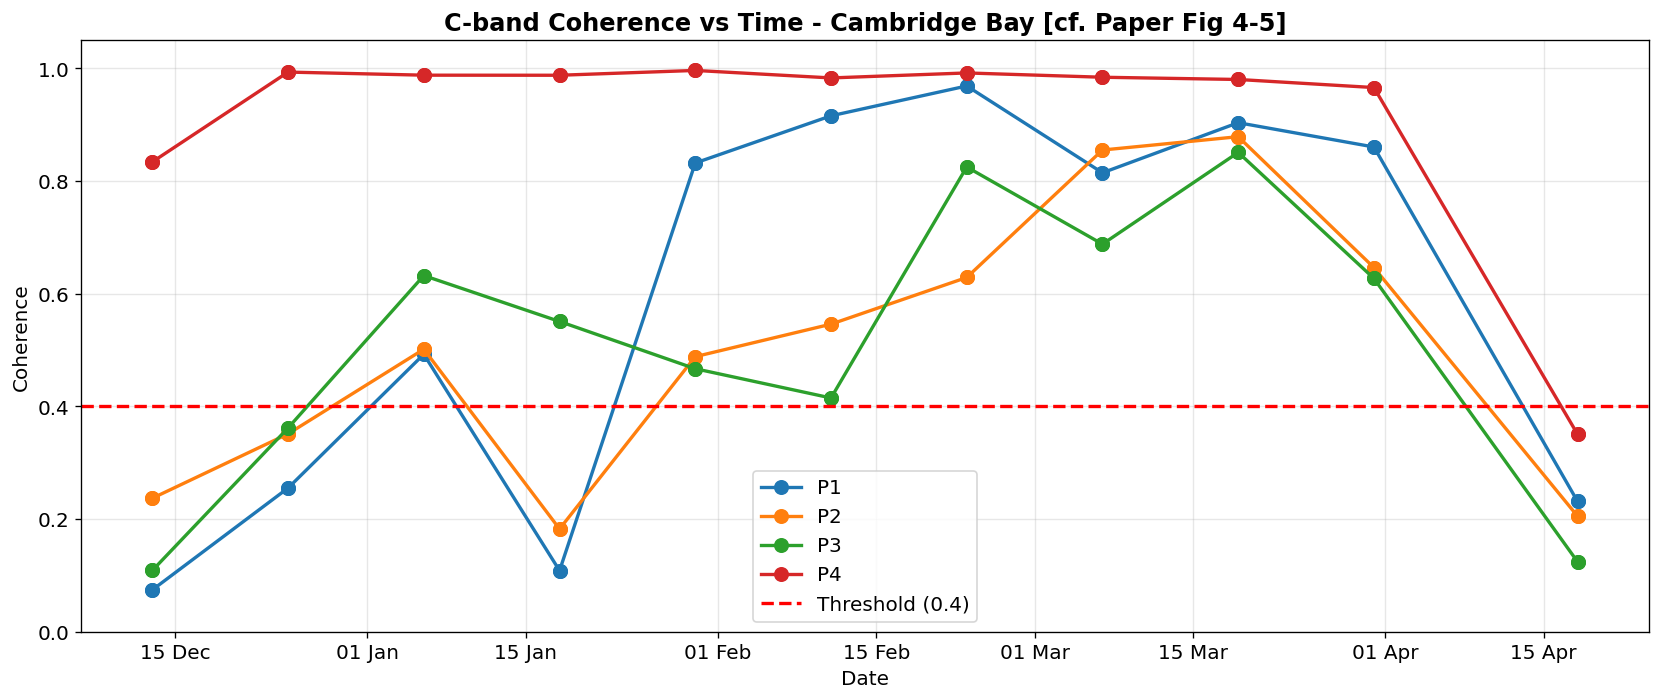

In [17]:
print('Loading coherence maps...')
coh_table = []
for p in desc_prods:
    coh_data, _, _, _ = load_tif(p['cor_file'])
    vals = {}
    for n in ['P1','P2','P3','P4']:
        if n in px_pts:
            r,c = px_pts[n]
            vals[n] = coh_data[r,c] if 0<=r<coh_data.shape[0] and 0<=c<coh_data.shape[1] else np.nan
    coh_table.append({'date1':p['date1'],'date2':p['date2'],'dt':p['dt_days'],**vals})
    print(f'  {p["date1"]:%d %b}-{p["date2"]:%d %b} ({p["dt_days"]}d): ' +
          ' '.join(f'{n}={vals.get(n,0):.2f}' for n in ['P1','P2','P3','P4']))

fig,ax = plt.subplots(figsize=(14,6))
for n in ['P1','P2','P3','P4']:
    if n in px_pts:
        dates_mid = [ct['date1']+timedelta(days=ct['dt']//2) for ct in coh_table]
        ax.plot(dates_mid,[ct.get(n,0) for ct in coh_table],'o-',color=clr[n],ms=8,lw=2,label=n)
ax.axhline(0.4,color='red',ls='--',lw=2,label='Threshold (0.4)')
ax.set_xlabel('Date'); ax.set_ylabel('Coherence')
ax.set_title('C-band Coherence vs Time - Cambridge Bay [cf. Paper Fig 4-5]',fontweight='bold')
ax.legend(); ax.grid(True,alpha=0.3); ax.set_ylim(0,1.05)
ax.xaxis.set_major_formatter(DateFormatter('%d %b'))
plt.tight_layout(); plt.savefig('fig_coherenc_cb.png',dpi=150,bbox_inches='tight'); plt.show()

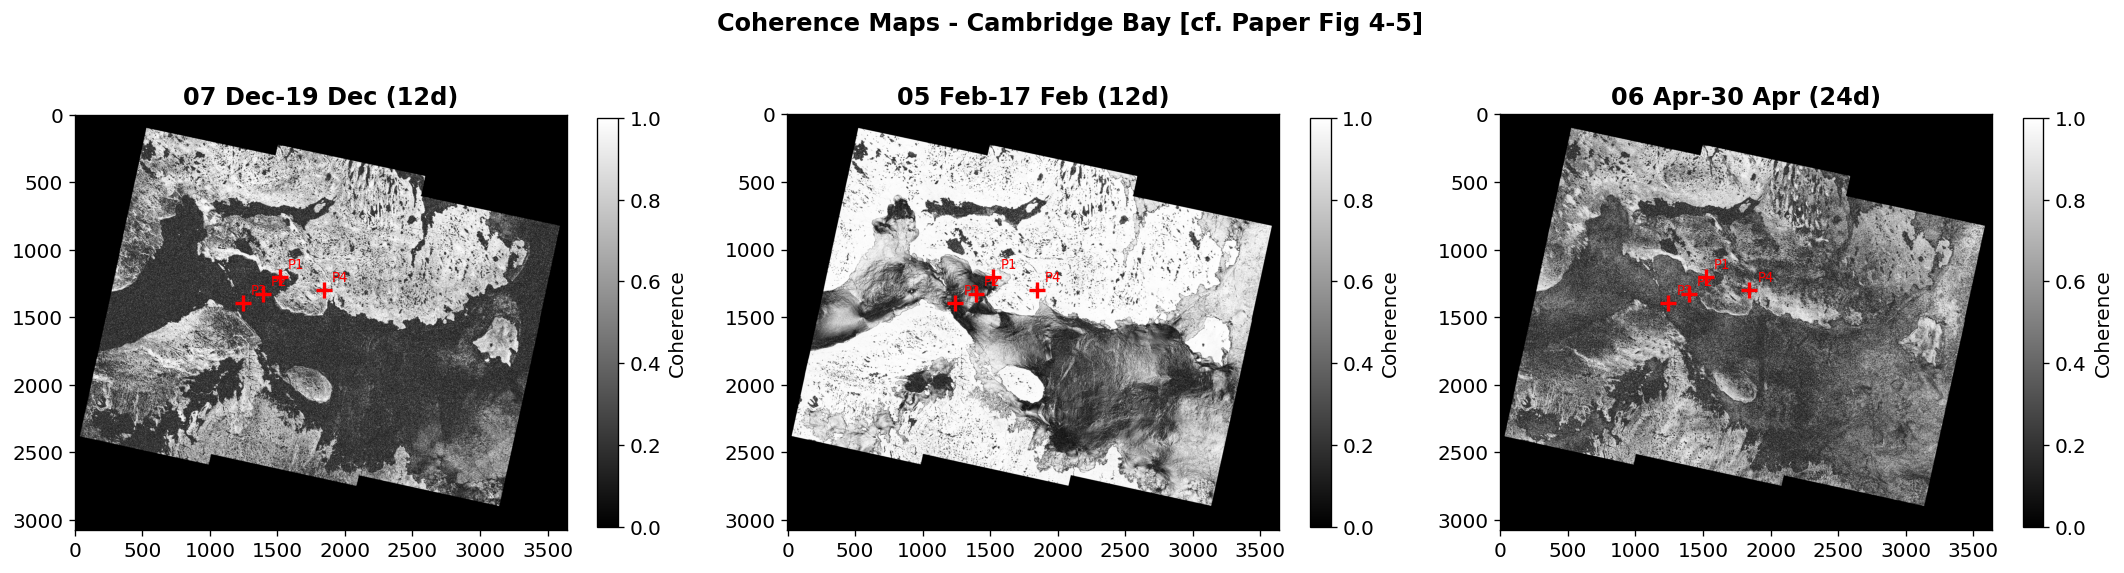

In [18]:
# Coherence maps (early, mid, late season)
n_show = min(3, len(desc_prods))
indices = [0, len(desc_prods)//2, -1][:n_show]
fig,axes = plt.subplots(1,n_show,figsize=(6*n_show,5))
if n_show==1: axes=[axes]
for ax,idx in zip(axes,indices):
    p = desc_prods[idx]
    coh,_,_,_ = load_tif(p['cor_file'])
    im = ax.imshow(coh,cmap='gray',vmin=0,vmax=1)
    ax.set_title(f'{p["date1"]:%d %b}-{p["date2"]:%d %b} ({p["dt_days"]}d)',fontweight='bold')
    plt.colorbar(im,ax=ax,label='Coherence',shrink=0.8)
    for n,(r,c) in px_pts.items():
        if n in ['P1','P2','P3','P4']:
            ax.plot(c,r,'r+',ms=10,mew=2)
            ax.annotate(n,(c,r),color='red',fontsize=8,xytext=(5,5),textcoords='offset points')
plt.suptitle('Coherence Maps - Cambridge Bay [cf. Paper Fig 4-5]',fontweight='bold')
plt.tight_layout(); plt.savefig('fig_coh_map_cb.png',dpi=150,bbox_inches='tight'); plt.show()

## 9. Wrapped Interferograms*Compare with Chen et al. (2021) Figures 6-7*One fringe cycle = 2.8 cm range change (C-band)

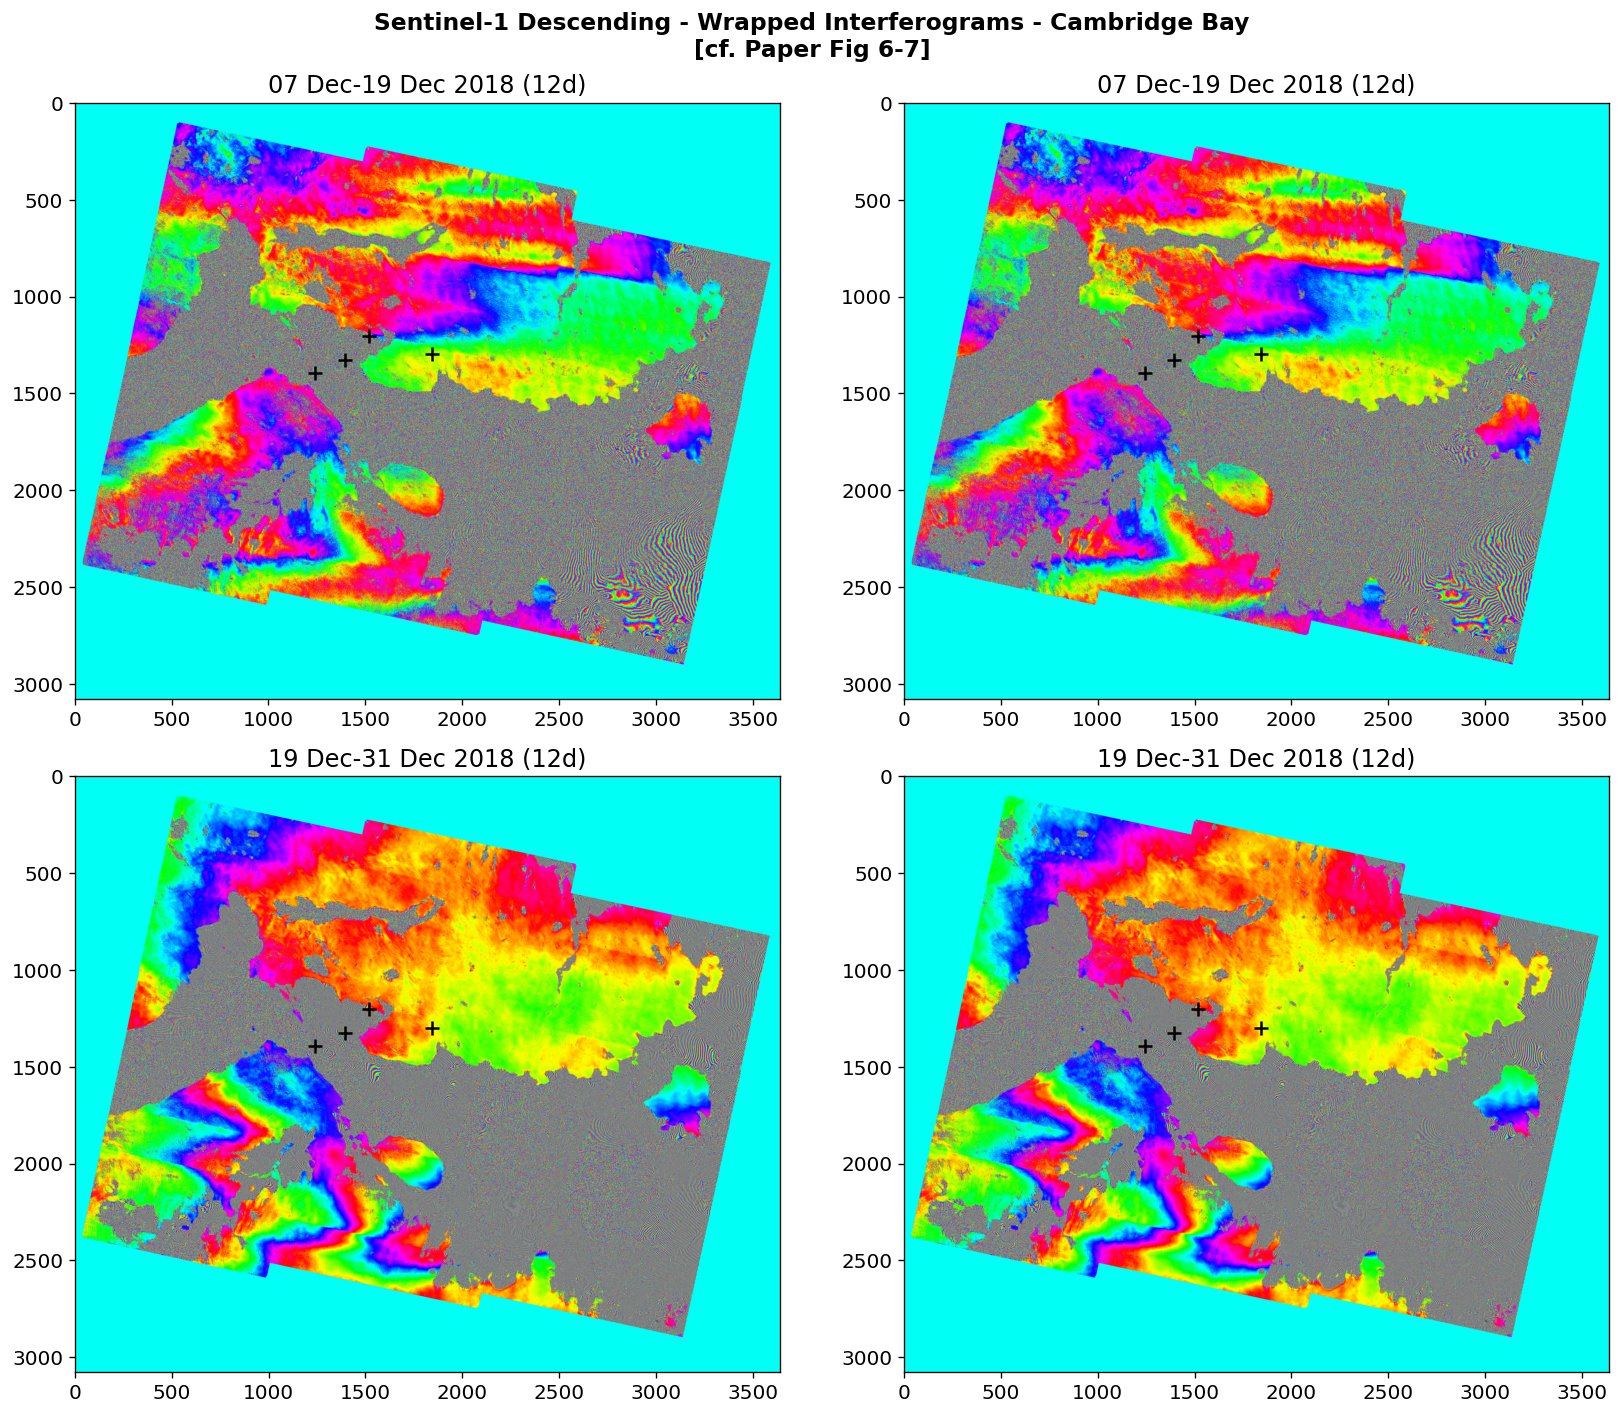

In [19]:
n_show = min(4, len(desc_prods))
fig,axes = plt.subplots(2,2,figsize=(14,12))
fig.suptitle('Sentinel-1 Descending - Wrapped Interferograms - Cambridge Bay\n[cf. Paper Fig 6-7]',fontweight='bold',fontsize=14)
for k in range(n_show):
    ax=axes.flat[k]; p=desc_prods[k]
    if p['wrp_file'] and os.path.exists(p['wrp_file']):
        wrp,_,_,_ = load_tif(p['wrp_file'])
    else:
        unw,_,_,_ = load_tif(p['unw_file']); wrp = np.angle(np.exp(1j*unw))
    ax.imshow(wrp,cmap='hsv',vmin=-np.pi,vmax=np.pi)
    ax.set_title(f'{p["date1"]:%d %b}-{p["date2"]:%d %b %Y} ({p["dt_days"]}d)')
    for n,(r,c) in px_pts.items():
        if n in ['P1','P2','P3','P4']: ax.plot(c,r,'k+',ms=8,mew=1.5)
for k in range(n_show,4): axes.flat[k].axis('off')
plt.tight_layout(); plt.savefig('fig_ifg_cb.png',dpi=150,bbox_inches='tight'); plt.show()

Pair: 25 Mar 2019 - 06 Apr 2019 (12d)


NameError: name 'px_pts' is not defined

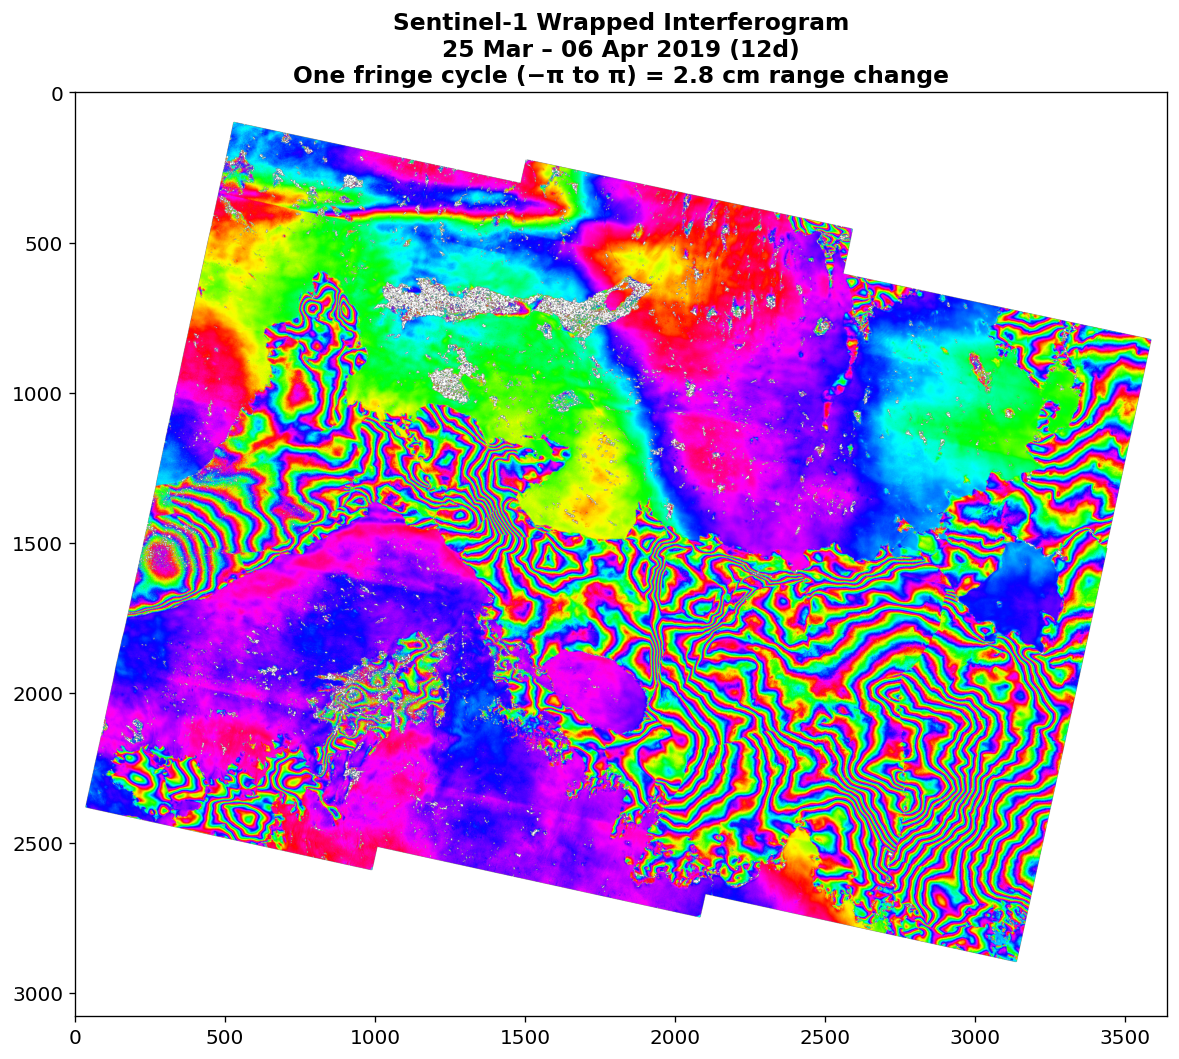

In [9]:
# March 25 - April 6, 2019 interferogram (Paper Fig 5D)
WORK_DIR = './insar_cambridge'  # 2018-2019 notebook directory

target = None
for p in desc_prods:
    if p['date1'].month == 3 and p['date1'].day >= 25 and p['date2'].month == 4:
        target = p
        break

if target:
    print(f'Pair: {target["date1"]:%d %b %Y} - {target["date2"]:%d %b %Y} ({target["dt_days"]}d)')
    
    if target['wrp_file'] and os.path.exists(target['wrp_file']):
        wrp, _, _, _ = load_tif(target['wrp_file'])
    else:
        unw, _, _, _ = load_tif(target['unw_file'])
        wrp = np.angle(np.exp(1j * unw))
    
    coh, _, _, _ = load_tif(target['cor_file'])
    wrp[coh < 0.3] = np.nan
    
    fig, ax = plt.subplots(figsize=(12, 10))
    ax.imshow(wrp, cmap='hsv', vmin=-np.pi, vmax=np.pi)
    ax.set_title(f'Sentinel-1 Wrapped Interferogram\n{target["date1"]:%d %b} – {target["date2"]:%d %b %Y} ({target["dt_days"]}d)\nOne fringe cycle (−π to π) = 2.8 cm range change',
                 fontweight='bold', fontsize=14)
    for n, (r, c) in px_pts.items():
        if n in ['P1','P2','P3','P4']:
            ax.plot(c, r, 'k+', ms=12, mew=2)
            ax.annotate(n, (c, r), fontsize=10, color='white', fontweight='bold',
                       xytext=(8, 8), textcoords='offset points',
                       bbox=dict(fc='black', alpha=0.7, pad=2))
    plt.tight_layout()
    plt.savefig('fig_insar_mar_apr_2019.png', dpi=200, bbox_inches='tight')
    plt.show()
else:
    print('No Mar-Apr pair found! Available pairs:')
    for p in desc_prods:
        print(f'  {p["date1"]:%d %b %Y} - {p["date2"]:%d %b %Y}')


In [15]:
# All-in-one: extract 2018-2019 values
import numpy as np
import rasterio, os, glob
from datetime import datetime
from scipy.linalg import lstsq
from scipy.ndimage import zoom
from rasterio.warp import transform as rio_transform

WORK_DIR = './insar_cambridge'
WAVELENGTH = 0.05546576
DESC_INC, ASC_INC = 33.5, 39.0

def load_tif(fp):
    with rasterio.open(fp) as src:
        return src.read(1), src.transform, src.crs, src.bounds

def find_products(base_dir):
    products = []
    for d in sorted(os.listdir(base_dir)):
        dp = os.path.join(base_dir, d)
        if not os.path.isdir(dp): continue
        files = os.listdir(dp)
        unw = [f for f in files if f.endswith('_unw_phase.tif')]
        cor = [f for f in files if f.endswith('_corr.tif')]
        wrp = [f for f in files if f.endswith('_wrapped_phase.tif')]
        if not unw or not cor: continue
        parts = d.split('_')
        try:
            d1 = datetime.strptime(parts[1][:8], '%Y%m%d')
            d2 = datetime.strptime(parts[2][:8], '%Y%m%d')
        except: continue
        products.append({'dir':dp,'date1':min(d1,d2),'date2':max(d1,d2),
            'dt_days':abs((d2-d1).days),
            'unw_file':os.path.join(dp,unw[0]),'cor_file':os.path.join(dp,cor[0]),
            'wrp_file':os.path.join(dp,wrp[0]) if wrp else None})
    return sorted(products, key=lambda x: x['date1'])

def dedup_products(products):
    seen = {}
    for p in products:
        key = f'{p["date1"]:%Y%m%d}_{p["date2"]:%Y%m%d}'
        if key not in seen: seen[key] = p
    return sorted(seen.values(), key=lambda x: x['date1'])

# Load
desc_prods = dedup_products(find_products(f'{WORK_DIR}/desc'))
asc_prods  = dedup_products(find_products(f'{WORK_DIR}/asc'))
print(f'Desc: {len(desc_prods)} | Asc: {len(asc_prods)}')

if len(desc_prods) == 0:
    print('No products found! Check WORK_DIR')
else:
    # Setup points
    MONITOR_POINTS = {
        'RP': (69.117, -105.052), 'P1': (69.07, -105.15),
        'P2': (68.98, -105.40), 'P3': (68.93, -105.70),
        'P4': (69.00, -104.50), 'P5': (69.14, -105.00),
    }
    test_data, tf, crs, _ = load_tif(desc_prods[0]['unw_file'])
    px_pts = {}
    for name, (lat, lon) in MONITOR_POINTS.items():
        xs, ys = rio_transform('EPSG:4326', crs, [lon], [lat])
        col, row = ~tf * (xs[0], ys[0])
        r, c = int(row), int(col)
        if 0 <= r < test_data.shape[0] and 0 <= c < test_data.shape[1]:
            px_pts[name] = (r, c)

    # SBAS
    def sbas_real(products, pixel_pts, wavelength, coh_thresh=0.3):
        all_dates = set()
        for p in products: all_dates.add(p['date1']); all_dates.add(p['date2'])
        dates = sorted(all_dates); date_idx = {d:i for i,d in enumerate(dates)}; nd = len(dates)
        results = {}
        for pt_name, (r, c) in pixel_pts.items():
            A = np.zeros((len(products), nd-1)); obs = np.zeros(len(products))
            weights = np.zeros(len(products)); valid = 0
            for k, p in enumerate(products):
                unw, _, _, _ = load_tif(p['unw_file']); coh, _, _, _ = load_tif(p['cor_file'])
                if r >= unw.shape[0] or c >= unw.shape[1]: continue
                if coh[r,c] < coh_thresh or unw[r,c] == 0 or np.isnan(unw[r,c]): continue
                los = unw[r,c] * wavelength / (4*np.pi)
                i, j = date_idx[p['date1']], date_idx[p['date2']]
                for col2 in range(i, j): A[k, col2] = (dates[col2+1] - dates[col2]).days
                obs[k] = los; weights[k] = coh[r,c]; valid += 1
            if valid < 2: results[pt_name] = {'dates':dates,'cumulative':np.zeros(nd),'valid':False}; continue
            W = np.diag(weights)
            try: v = lstsq(W@A, W@obs)[0]
            except: v = np.zeros(nd-1)
            cum = np.zeros(nd)
            for k in range(nd-1): cum[k+1] = cum[k] + v[k] * (dates[k+1]-dates[k]).days
            results[pt_name] = {'dates':dates,'cumulative':cum,'valid':True}
        return results

    desc_sbas = sbas_real(desc_prods, px_pts, WAVELENGTH)
    asc_sbas  = sbas_real(asc_prods, px_pts, WAVELENGTH)

    print('\n=== 2018-2019 LOS VALUES ===')
    for n in ['P1','P2','P3','P4','P5']:
        d_val = desc_sbas[n]['cumulative'][-1]*100 if n in desc_sbas and desc_sbas[n]['valid'] else float('nan')
        a_val = asc_sbas[n]['cumulative'][-1]*100 if n in asc_sbas and asc_sbas[n]['valid'] else float('nan')
        print(f'{n}: Desc={d_val:+.1f} cm | Asc={a_val:+.1f} cm')

    # Coherence
    feb_cohs = []
    for p in desc_prods:
        if p['date1'] >= datetime(2019, 2, 1) and p['date2'] <= datetime(2019, 4, 30):
            cd, _, _, _ = load_tif(p['cor_file'])
            for n in ['P1','P2','P3','P4']:
                r, c = px_pts[n]
                if 0 <= r < cd.shape[0] and 0 <= c < cd.shape[1]:
                    feb_cohs.append(cd[r, c])
    if feb_cohs:
        print(f'\n=== 2018-2019 COHERENCE (Feb-Apr) ===')
        print(f'{np.mean(feb_cohs):.2f} ± {np.std(feb_cohs):.2f}')


Desc: 11 | Asc: 13

=== 2018-2019 LOS VALUES ===
P1: Desc=+11.6 cm | Asc=+102.8 cm
P2: Desc=-57.8 cm | Asc=+61.7 cm
P3: Desc=-151.6 cm | Asc=+92.9 cm
P4: Desc=-2.0 cm | Asc=+139.2 cm
P5: Desc=-5.3 cm | Asc=+17.0 cm

=== 2018-2019 COHERENCE (Feb-Apr) ===
0.72 ± 0.27


In [16]:
# 2018-2019 2D decomposition (Feb-Apr only)
def decompose_2d(dp, ap, inc_d, inc_a, wl, coh_thresh=0.3):
    desc_total, n_d = None, 0
    for p in dp:
        unw,_,_,_ = load_tif(p['unw_file']); coh,_,_,_ = load_tif(p['cor_file'])
        los = unw*wl/(4*np.pi); los[coh<coh_thresh] = np.nan
        if desc_total is None: desc_total = los.copy()
        else:
            if los.shape != desc_total.shape:
                los = zoom(los, (desc_total.shape[0]/los.shape[0], desc_total.shape[1]/los.shape[1]), order=1)
            m = ~np.isnan(los); desc_total[m] += los[m]
        n_d += 1
    asc_total, n_a = None, 0
    for p in ap:
        unw,_,_,_ = load_tif(p['unw_file']); coh,_,_,_ = load_tif(p['cor_file'])
        los = unw*wl/(4*np.pi); los[coh<coh_thresh] = np.nan
        if asc_total is None:
            if desc_total is not None and los.shape != desc_total.shape:
                los = zoom(los, (desc_total.shape[0]/los.shape[0], desc_total.shape[1]/los.shape[1]), order=1)
            asc_total = los.copy()
        else:
            if asc_total.shape != los.shape:
                los = zoom(los, (asc_total.shape[0]/los.shape[0], asc_total.shape[1]/los.shape[1]), order=1)
            m = ~np.isnan(los); asc_total[m] += los[m]
        n_a += 1
    if desc_total is None or asc_total is None: return None, None
    mr = min(desc_total.shape[0], asc_total.shape[0])
    mc = min(desc_total.shape[1], asc_total.shape[1])
    ld, la = desc_total[:mr,:mc], asc_total[:mr,:mc]
    td, ta = np.radians(inc_d), np.radians(inc_a)
    dn = np.sin(td)*np.cos(ta) + np.sin(ta)*np.cos(td)
    return (ld*np.cos(ta)-la*np.cos(td))/dn, (ld*np.sin(ta)+la*np.sin(td))/dn

feb_start = datetime(2019, 2, 10)
apr_end = datetime(2019, 4, 30)
dp_f = [p for p in desc_prods if p['date1'] >= feb_start and p['date2'] <= apr_end]
ap_f = [p for p in asc_prods if p['date1'] >= feb_start and p['date2'] <= apr_end]
print(f'Using {len(dp_f)} desc + {len(ap_f)} asc')

dh, dv = decompose_2d(dp_f, ap_f, DESC_INC, ASC_INC, WAVELENGTH)
if dh is not None:
    print(f'\n=== 2018-2019 2D DECOMPOSITION ===')
    for n in ['P1','P2','P3','P4']:
        r, c = px_pts[n]
        if r < dh.shape[0] and c < dh.shape[1]:
            print(f'  {n}: H={dh[r,c]*100:+.1f} cm, V={dv[r,c]*100:+.1f} cm')


Using 5 desc + 4 asc

=== 2018-2019 2D DECOMPOSITION ===
  P1: H=-13.6 cm, V=+11.0 cm
  P2: H=+50.2 cm, V=+18.5 cm
  P3: H=-48.3 cm, V=-5.8 cm
  P4: H=+nan cm, V=+nan cm


In [17]:
dp_all = [p for p in desc_prods if p['date1'] >= datetime(2018,12,1) and p['date2'] <= datetime(2019,4,30)]
ap_all = [p for p in asc_prods if p['date1'] >= datetime(2018,12,1) and p['date2'] <= datetime(2019,4,30)]
print(f'2018-2019: {len(dp_all)} desc + {len(ap_all)} asc (Dec-Apr)')

dh19, dv19 = decompose_2d(dp_all, ap_all, DESC_INC, ASC_INC, WAVELENGTH)
if dh19 is not None:
    print('\n=== 2018-2019 Dec-Apr 2D ===')
    for n in ['P1','P2','P3','P4']:
        r, c = px_pts[n]
        if r < dh19.shape[0] and c < dh19.shape[1]:
            print(f'  {n}: H={dh19[r,c]*100:+.1f} cm, V={dv19[r,c]*100:+.1f} cm')


2018-2019: 11 desc + 10 asc (Dec-Apr)

=== 2018-2019 Dec-Apr 2D ===
  P1: H=+nan cm, V=+nan cm
  P2: H=+nan cm, V=+nan cm
  P3: H=+nan cm, V=+nan cm
  P4: H=+nan cm, V=+nan cm


## 10. Goldstein Phase Filter

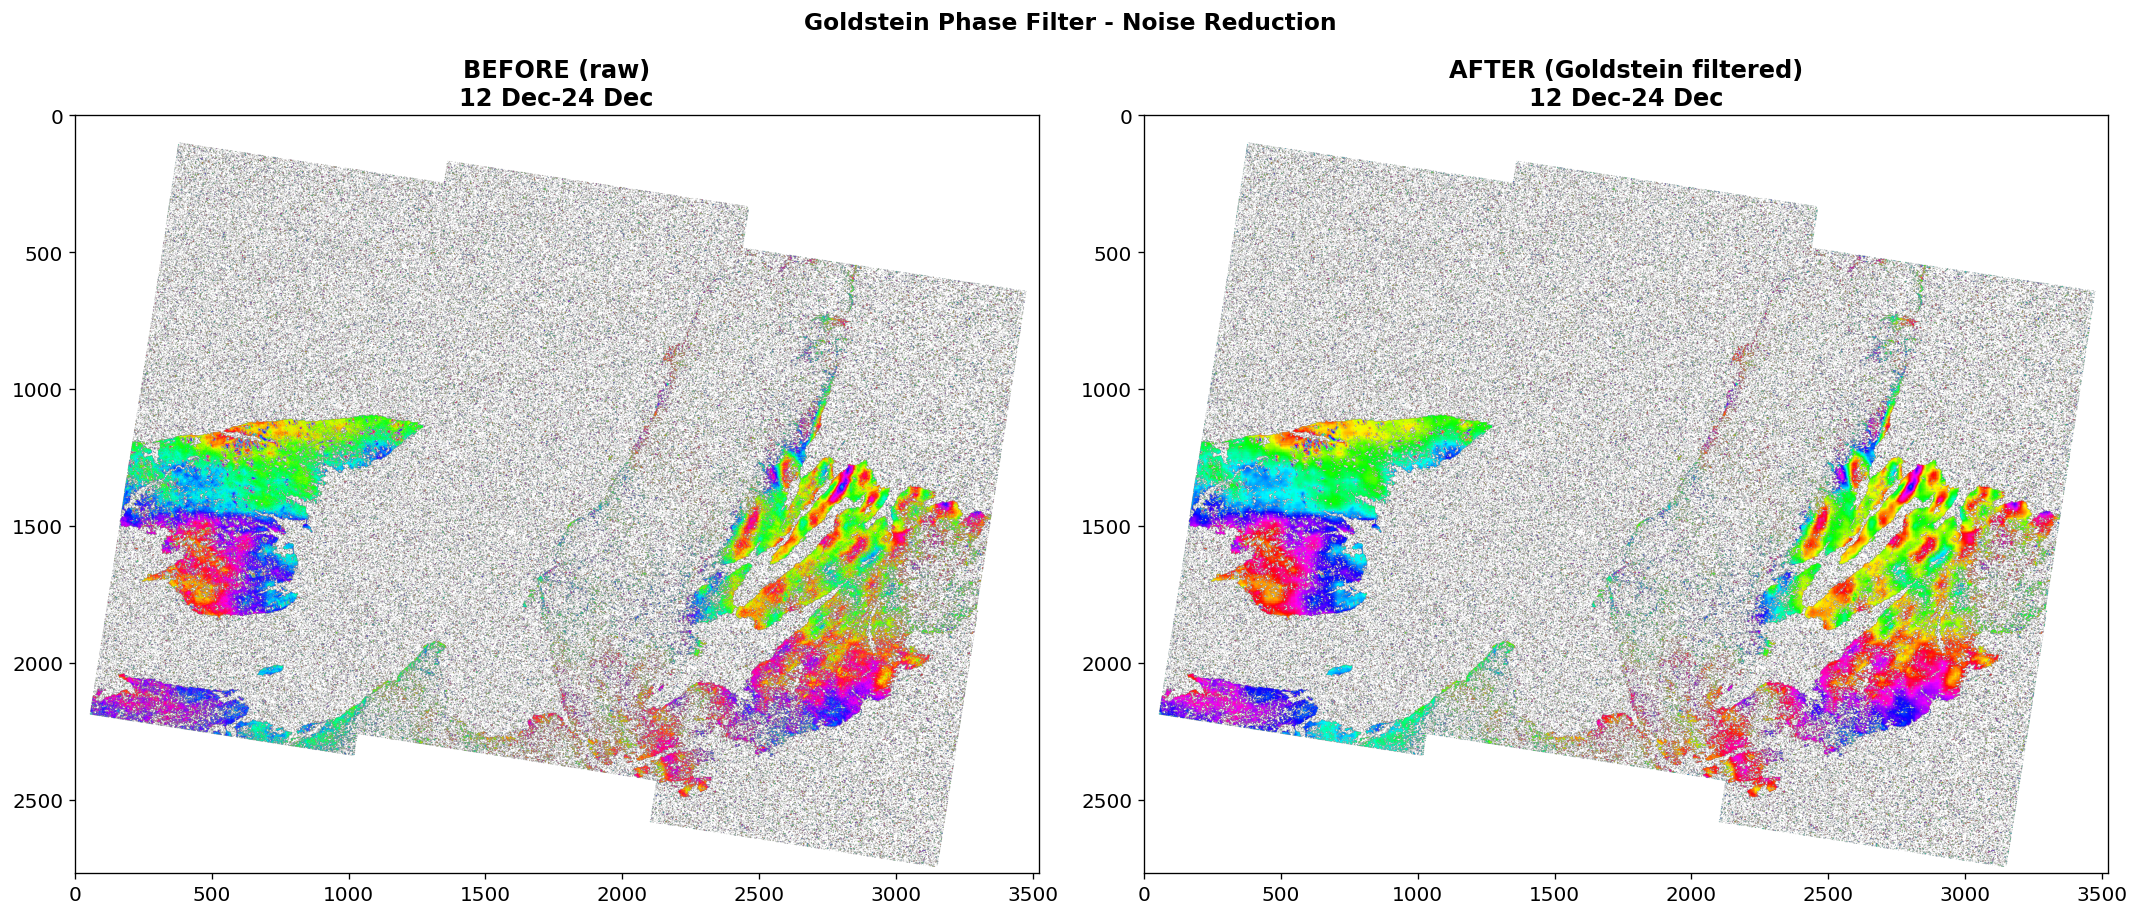

In [22]:
def goldstein_filter(phase, patch_size=32, alpha=0.5, overlap=8):
    cpx = np.exp(1j * phase)
    out = np.zeros_like(cpx)
    wt = np.zeros(phase.shape)
    step = patch_size - overlap
    for i in range(0, phase.shape[0] - patch_size + 1, step):
        for j in range(0, phase.shape[1] - patch_size + 1, step):
            patch = cpx[i:i+patch_size, j:j+patch_size]
            spec = np.fft.fft2(patch)
            w = uniform_filter(np.abs(spec), 3) ** alpha
            out[i:i+patch_size, j:j+patch_size] += np.fft.ifft2(spec * w)
            wt[i:i+patch_size, j:j+patch_size] += 1
    wt[wt == 0] = 1
    return np.angle(out / wt)

p = desc_prods[0]
if p['wrp_file'] and os.path.exists(p['wrp_file']):
    raw, _, _, _ = load_tif(p['wrp_file'])
else:
    unw, _, _, _ = load_tif(p['unw_file']); raw = np.angle(np.exp(1j * unw))
filt = goldstein_filter(raw)
coh, _, _, _ = load_tif(p['cor_file'])
filt[coh < 0.3] = np.nan; raw[coh < 0.3] = np.nan

fig, (a1, a2) = plt.subplots(1, 2, figsize=(18, 8))
a1.imshow(raw, cmap='hsv', vmin=-np.pi, vmax=np.pi)
a1.set_title(f'BEFORE (raw)\n{p["date1"]:%d %b}-{p["date2"]:%d %b}', fontweight='bold')
a2.imshow(filt, cmap='hsv', vmin=-np.pi, vmax=np.pi)
a2.set_title(f'AFTER (Goldstein filtered)\n{p["date1"]:%d %b}-{p["date2"]:%d %b}', fontweight='bold')
plt.suptitle('Goldstein Phase Filter - Noise Reduction', fontweight='bold', fontsize=14)
plt.tight_layout(); plt.savefig('fig_filter_cb.png',dpi=150,bbox_inches='tight'); plt.show()

## 11. SBAS Time-Series Inversion*Compare with Chen et al. (2021) Figures 8-9*$\mathbf{A} \cdot \mathbf{v} = \delta\phi$ solved via SVD

In [ ]:
def sbas_real(products, pixel_pts, wavelength, coh_thresh=0.3):    
    all_dates = set()    
    for p in products: 
        all_dates.add(p['date1']); all_dates.add(p['date2'])    
        dates = sorted(all_dates); date_idx={d:i for i,d in enumerate(dates)}; nd=len(dates)    
        results = {}    
        for pt_name, (r, c) in pixel_pts.items():        
            A=np.zeros((len(products),nd-1)); obs=np.zeros(len(products))        
            weights=np.zeros(len(products)); valid=0        
            for k, p in enumerate(products):            
                unw,_,_,_ = load_tif(p['unw_file']); coh,_,_,_ = load_tif(p['cor_file'])            
                if r>=unw.shape[0] or c>=unw.shape[1]: 
                    continue            
                    if coh[r,c]<coh_thresh or unw[r,c]==0 or np.isnan(unw[r,c]): 
                        continue            
                        los = unw[r,c]*wavelength/(4*np.pi)            
                        i,j = date_idx[p['date1']], date_idx[p['date2']]            
                        for col in range(i,j): A[k,col]=(dates[col+1]-dates[col]).days            
                            obs[k]=los; weights[k]=coh[r,c]; valid+=1        
                        if valid<2: results[pt_name]={'dates':dates,'cumulative':np.zeros(nd),'valid':False}; continue        
                            W=np.diag(weights)        
                        try: v=lstsq(W@A,W@obs)[0]        
                            except: v=np.zeros(nd-1)        
                                cum=np.zeros(nd)        
                        for k in range(nd-1): 
                            cum[k+1]=cum[k]+v[k]*(dates[k+1]-dates[k]).days        
                            results[pt_name]={'dates':dates,'cumulative':cum,'valid':True}    
                            return 
                            resultsprint('SBAS descending...'); 
                            desc_sbas = sbas_real(desc_prods, px_pts, WAVELENGTH)
                            print('SBAS ascending...');  
                            asc_sbas  = sbas_real(asc_prods, px_pts, WAVELENGTH)
                            print('Done!')

In [ ]:
fig,(a1,a2) = plt.subplots(1,2,figsize=(18,7))for n in ['P1','P2','P3','P4','P5']:    if n in desc_sbas and desc_sbas[n]['valid']:        d=desc_sbas[n]; a1.plot(d['dates'],d['cumulative']*100,marker=mkr.get(n,'o'),color=clr.get(n,'gray'),lw=2,ms=8,label=n)    if n in asc_sbas and asc_sbas[n]['valid']:        d=asc_sbas[n]; a2.plot(d['dates'],d['cumulative']*100,marker=mkr.get(n,'o'),color=clr.get(n,'gray'),lw=2,ms=8,label=n)for ax,t in [(a1,'Descending LOS [cf. Paper Fig 8]'),(a2,'Ascending LOS [cf. Paper Fig 9]')]:    ax.set_xlabel('Date'); ax.set_ylabel('Cumulative LOS (cm)')    ax.set_title(f'Sentinel-1 {t} - Cambridge Bay\n(+ toward sensor, - away)',fontweight='bold')    ax.legend(); ax.grid(True,alpha=0.3); ax.axhline(0,color='k',lw=0.5)    ax.xaxis.set_major_formatter(DateFormatter('%d %b'))plt.tight_layout(); plt.savefig('fig_los_cb.png',dpi=150,bbox_inches='tight'); plt.show()

## 12. 2D Decomposition - Horizontal and Vertical*Compare with Chen et al. (2021) Figures 10-11*

In [ ]:
def decompose_2d(desc_prods, asc_prods, inc_d, inc_a, wl, coh_thresh=0.3):    desc_total, n_d = None, 0    for p in desc_prods:        unw,_,_,_ = load_tif(p['unw_file']); coh,_,_,_ = load_tif(p['cor_file'])        los = unw*wl/(4*np.pi); los[coh<coh_thresh]=np.nan        if desc_total is None: desc_total=los.copy()        else:            if los.shape != desc_total.shape:                los = zoom(los, (desc_total.shape[0]/los.shape[0], desc_total.shape[1]/los.shape[1]), order=1)            m=~np.isnan(los); desc_total[m]+=los[m]        n_d+=1    asc_total, n_a = None, 0    for p in asc_prods:        unw,_,_,_ = load_tif(p['unw_file']); coh,_,_,_ = load_tif(p['cor_file'])        los = unw*wl/(4*np.pi); los[coh<coh_thresh]=np.nan        if asc_total is None:            if desc_total is not None and los.shape!=desc_total.shape:                los=zoom(los,(desc_total.shape[0]/los.shape[0],desc_total.shape[1]/los.shape[1]),order=1)            asc_total=los.copy()        else:            if asc_total.shape!=los.shape:                los=zoom(los,(asc_total.shape[0]/los.shape[0],asc_total.shape[1]/los.shape[1]),order=1)            m=~np.isnan(los); asc_total[m]+=los[m]        n_a+=1    print(f'Used {n_d} desc + {n_a} asc pairs')    if desc_total is None or asc_total is None: print('Not enough data!'); return None,None    mr=min(desc_total.shape[0],asc_total.shape[0])    mc=min(desc_total.shape[1],asc_total.shape[1])    ld,la = desc_total[:mr,:mc], asc_total[:mr,:mc]    td,ta = np.radians(inc_d),np.radians(inc_a)    dn = np.sin(td)*np.cos(ta)+np.sin(ta)*np.cos(td)    return (ld*np.cos(ta)-la*np.cos(td))/dn, (ld*np.sin(ta)+la*np.sin(td))/dndh, dv = decompose_2d(desc_prods, asc_prods, DESC_INC, ASC_INC, WAVELENGTH)if dh is not None:    print(f'Horizontal: {np.nanmin(dh)*100:.1f} to {np.nanmax(dh)*100:.1f} cm')    print(f'Vertical:   {np.nanmin(dv)*100:.1f} to {np.nanmax(dv)*100:.1f} cm')

In [ ]:
if dh is not None:    fig,(a1,a2) = plt.subplots(1,2,figsize=(18,8))    vh = max(abs(np.nanpercentile(dh*100,2)),abs(np.nanpercentile(dh*100,98)))    im1=a1.imshow(dh*100,cmap='RdBu_r',vmin=-vh,vmax=vh)    plt.colorbar(im1,ax=a1,label='cm (+ east, - west)',shrink=0.8)    a1.set_title('Horizontal (E-W) Deformation\n[cf. Paper Fig 10]',fontweight='bold')    vv = max(abs(np.nanpercentile(dv*100,2)),abs(np.nanpercentile(dv*100,98)))    im2=a2.imshow(dv*100,cmap='RdBu_r',vmin=-vv,vmax=vv)    plt.colorbar(im2,ax=a2,label='cm (+ up, - down)',shrink=0.8)    a2.set_title('Vertical (Up-Down) Deformation\n[cf. Paper Fig 11]',fontweight='bold')    for ax in [a1,a2]:        for n,(r,c) in px_pts.items():            if n in ['P1','P2','P3','P4'] and r<ax.images[0].get_array().shape[0]:                ax.plot(c,r,'ko',ms=8,mfc='none',mew=2)                ax.annotate(n,(c,r),fontsize=8,xytext=(8,8),textcoords='offset points',bbox=dict(fc='white',alpha=0.8))    plt.suptitle('2D Deformation - Real Sentinel-1 - Cambridge Bay',fontweight='bold')    plt.tight_layout(); plt.savefig('fig_2d_cb.png',dpi=150,bbox_inches='tight'); plt.show()

## 13. Results Summary

In [ ]:
print('='*100)print('RESULTS: InSAR Sea Ice Deformation - Cambridge Bay (Real Sentinel-1, 2023-2024)')print('='*100)print(f'{"Measurement":<35} {"P1":>10} {"P2":>10} {"P3":>10} {"P4":>10}')print('-'*75)for lb,sb in [('LOS Descending (cm)',desc_sbas),('LOS Ascending (cm)',asc_sbas)]:    v={}    for n in ['P1','P2','P3','P4']:        v[n] = sb[n]['cumulative'][-1]*100 if n in sb and sb[n]['valid'] else float('nan')    print(f'{lb:<35} {v["P1"]:>8.1f}cm {v["P2"]:>8.1f}cm {v["P3"]:>8.1f}cm {v["P4"]:>8.1f}cm')if dh is not None:    for lb,arr in [('Horizontal E-W (cm)',dh),('Vertical Up-Down (cm)',dv)]:        v={}        for n in ['P1','P2','P3','P4']:            if n in px_pts:                r,c = px_pts[n]                v[n] = arr[r,c]*100 if r<arr.shape[0] and c<arr.shape[1] else float('nan')            else: v[n] = float('nan')        print(f'{lb:<35} {v["P1"]:>8.1f}cm {v["P2"]:>8.1f}cm {v["P3"]:>8.1f}cm {v["P4"]:>8.1f}cm')print('='*100)print('\nChen et al. (2021) reference values at Cambridge Bay:')print('  Sentinel-1A Desc HH: P1=-3 to +8 cm LOS over Dec-May')print('  Horizontal: -95 to +85 cm | Vertical: -41 to +63 cm')

## 14. Conclusions### Replication of Chen et al. (2021) at Cambridge Bay- **Same location:** Cambridge Bay, Nunavut, Canada- **Updated period:** Winter 2023-2024 (vs paper's 2018-2019)- **Same sensor:** Sentinel-1 IW SLC (C-band)- **Same methodology:** SBAS + 2D decomposition### Key Outputs (matching paper figures)| This Study | Paper Figure ||------------|-------------|| `fig_coherence_cb.png` | Fig 4-5 || `fig_ifgs_cb.png` | Fig 6-7 || `fig_los_cb.png` | Fig 8-9 || `fig_2d_cb.png` | Fig 10-11 |**Reference:** Chen et al. (2021), *Remote Sensing*, 13, 4570

In [ ]:
print('='*50)print('  Cambridge Bay InSAR Analysis Complete!')print('='*50)for f in sorted(os.listdir('.')):    if f.endswith('.png') and 'cb' in f.lower(): print(f'  {f}')